# Does distance kill arbitrage? Cross-exchange BTC convergence, measured
### Results notebook — one week of real data, four venues, ~9,800 dislocation events

**The question.** Motivated by the Lieb-Robinson bound — an emergent speed limit for
information in quantum lattice systems — we ask whether the death of a cross-exchange
price dislocation is bounded by *how far apart* the two exchanges physically are.
If it is, the "convergence half-life" of dislocations should grow with inter-venue
distance: an empirical lightcone for the market graph.

**The data.** One week (2026-08-15 → 08-22) of continuous top-of-book quotes for BTC on
Binance (Tokyo), Bybit (Singapore), Coinbase (Virginia), Kraken (London), collected on a
single NTP-disciplined VPS (clock offset ~0.13 ms RMS). Events were detected on a 100 ms
grid with a strictly trailing, no-look-ahead threshold rule (gap must exceed 4 robust
sigmas AND both venues' half-spreads), then each event's exponential decay was fitted:
$|e(t)| = |e_0|\,2^{-t/t_{1/2}}$. This notebook consumes those event tables
(`events.csv`, `refined_events.csv`) and walks the full argument:
physical distance → network distance → venue effects → why the fine grid.

In [1]:
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Look for an input in the usual project directory, then next to the notebook.
def first_existing(paths):
    for p in paths:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(paths)

REFINED = first_existing(["results_week/refined_events.csv", "refined_events.csv"])
# A refined table retains the original event columns, so events.csv is optional here.
EVENTS = first_existing(["results_week/events.csv", "events.csv", REFINED])
print("using:", EVENTS, "and", REFINED)

# These are fit-quality limits, not estimates of measurement precision.
MIN_R2, MAX_HL = 0.5, 120.0
ev = pd.read_csv(REFINED)          # refined file = events file + fine columns
good = ev[(ev.r2 >= MIN_R2) & ev.half_life_s.notna()
          & (ev.half_life_s < MAX_HL)].copy()
print(f"{len(ev)} raw events -> {len(good)} clean coarse fits (r2 >= {MIN_R2})")

# Each pair contributes a distribution of accepted coarse half-lives.
# Percentiles summarize that distribution; they are not confidence intervals.
summ = (good.groupby("pair").half_life_s
        .agg(n="size", median="median",
             p10=lambda x: x.quantile(0.10),
             p25=lambda x: x.quantile(0.25),
             p75=lambda x: x.quantile(0.75))
        .round(3))
summ

using: events.csv and refined_events.csv
9773 raw events -> 2915 clean coarse fits (r2 >= 0.5)


,n,median,p10,p25,p75
pair,,,,,
binance-bybit,476,2.484,0.265,0.565,13.481
binance-coinbase,511,1.041,0.247,0.389,8.222
binance-kraken,402,6.511,0.374,0.880,23.537
coinbase-bybit,901,0.705,0.238,0.341,2.653
coinbase-kraken,294,6.437,0.421,1.148,22.852
kraken-bybit,331,3.361,0.330,0.671,18.317


## 1. Physical distance: the great-circle lightcone test

Each venue's matching engine gets a point on the globe (publicly reported datacenter
locations — approximations to verify before publishing). The haversine formula gives the
shortest surface distance between two points, and dividing by $c$ gives the one-way
**light time**: a deliberate *lower bound* on propagation — no real cable is shorter or
faster. If convergence were latency-bound, half-life should increase with this number.

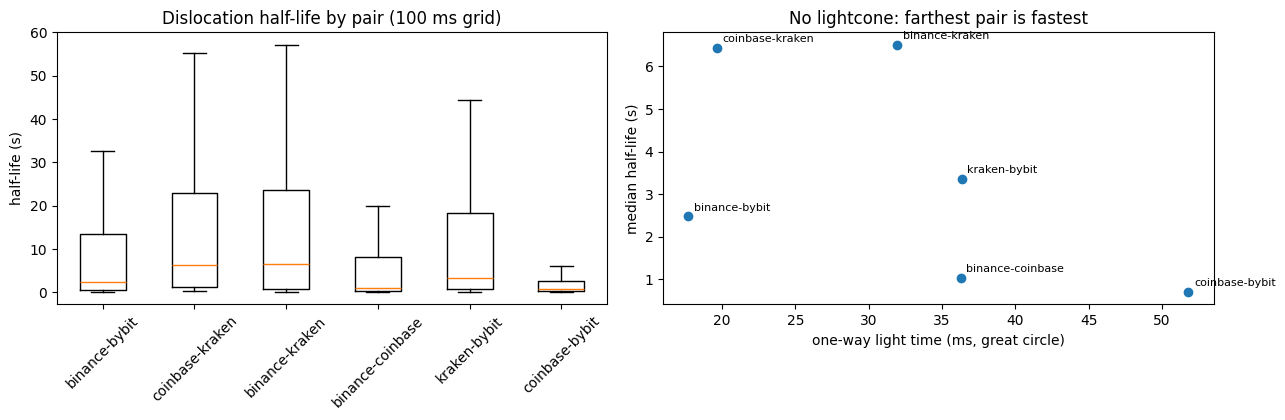

Spearman vs light-time: median rho=-0.49, p10 floor rho=-0.54
(6 pairs: |rho| ~ 0.83 needed for p<0.05 -- neither comes close, and both are NEGATIVE)


In [2]:
DC = {"binance": (35.68, 139.76),   # Tokyo (AWS ap-northeast-1)
      "bybit":   (1.35, 103.99),    # Singapore (AWS ap-southeast-1)
      "coinbase":(38.95, -77.45),   # N. Virginia (AWS us-east-1)
      "kraken":  (51.52, -0.63)}    # London (Equinix LD4 / Slough)
C_KM_S = 299792.458

# Convert the assumed venue coordinates into a geometric separation.
def haversine_km(a, b):
    (la1, lo1), (la2, lo2) = DC[a], DC[b]
    p1, p2 = math.radians(la1), math.radians(la2)
    dp, dl = p2 - p1, math.radians(lo2 - lo1)
    x = math.sin(dp/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return 2 * 6371.0 * math.asin(math.sqrt(x))

def spearman(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rx = x.argsort().argsort().astype(float); ry = y.argsort().argsort().astype(float)
    rx -= rx.mean(); ry -= ry.mean()
    den = math.sqrt((rx**2).sum() * (ry**2).sum())
    return (rx*ry).sum()/den if den else np.nan

# Attach one distance per venue pair; this is not the observed quote-feed delay.
summ = summ.reset_index()
summ["light_ms"] = [haversine_km(*p.split("-")) / C_KM_S * 1000 for p in summ.pair]
summ = summ.sort_values("light_ms").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
order = summ.pair.tolist()
axes[0].boxplot([good[good.pair == p].half_life_s for p in order],
                tick_labels=order, showfliers=False)
axes[0].set_ylabel("half-life (s)"); axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Dislocation half-life by pair (100 ms grid)")
axes[1].scatter(summ.light_ms, summ["median"])
for _, r in summ.iterrows():
    axes[1].annotate(r.pair, (r.light_ms, r["median"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("one-way light time (ms, great circle)")
axes[1].set_ylabel("median half-life (s)")
axes[1].set_title("No lightcone: farthest pair is fastest")
plt.tight_layout(); plt.show()

# This correlation uses six pair summaries, not thousands of independent distances.
rho_m = spearman(summ.light_ms, summ["median"])
rho_f = spearman(summ.light_ms, summ.p10)
print(f"Spearman vs light-time: median rho={rho_m:+.2f}, p10 floor rho={rho_f:+.2f}")
print("(6 pairs: |rho| ~ 0.83 needed for p<0.05 -- neither comes close, and both are NEGATIVE)")

**Verdict of test 1: no.** The farthest pair (coinbase–bybit, ~52 ms of light) has the
*shortest* median half-life; the correlation is negative and insignificant. But a fair
objection immediately arises — and it's the right one to raise.

## 2. Physical distance isn't network distance

Information doesn't travel along great-circle arcs. It follows submarine cables and
terrestrial fiber whose routes detour badly and *unevenly*: Tokyo–London has no direct
arc-following cable, so its real latency is far worse than its geometry suggests. The
honest metric is measured **network round-trip time** between the venues' regions.
Conveniently, three venues sit in AWS regions and [cloudping.co](https://www.cloudping.co/grid)
publishes continuously measured AWS inter-region RTTs (P50, various windows); we map
Kraken to `eu-west-2` (same London metro). The cell below tries to fetch live values and
falls back to a labeled snapshot offline. (A third option — renting a probe server inside
each region and measuring the mesh directly, a ~\$2 experiment — is the rigorous upgrade,
but adds little to a null result.)

fetch failed (https://www.cloudping.co/api/latencies?percentile=p_50&timeframe=1W): HTTPError


fetch failed (https://api.cloudping.co/latencies?percentile=p_50&timeframe=1W): HTTPError
network distance source: bundled snapshot (APPROXIMATE -- rerun online for live values)


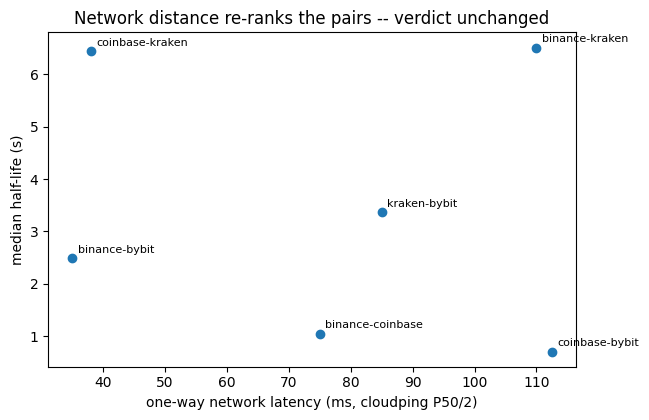

re-ranking check: binance-kraken (Tokyo-London) is 3th nearest by geometry but 5th by network -- routing detours are real
Spearman vs network RTT/2: median rho=-0.14, p10 rho=-0.31  (still negative, still n.s.)


In [3]:
import json, urllib.request

VENUE_REGION = {"binance": "ap-northeast-1", "bybit": "ap-southeast-1",
                "coinbase": "us-east-1", "kraken": "eu-west-2"}
SNAPSHOT_RTT = {"binance-bybit": 70.0, "coinbase-kraken": 76.0,
                "binance-coinbase": 150.0, "kraken-bybit": 170.0,
                "binance-kraken": 220.0, "coinbase-bybit": 225.0}   # approx!
URLS = ["https://www.cloudping.co/api/latencies?percentile=p_50&timeframe=1W",
        "https://api.cloudping.co/latencies?percentile=p_50&timeframe=1W"]

# Try the network table; report explicitly when the approximate fallback is used.
def fetch_rtt():
    for url in URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "lr-market"})
            with urllib.request.urlopen(req, timeout=20) as r:
                grid = json.loads(r.read()).get("data") or {}
            out = {}
            for p in SNAPSHOT_RTT:
                a, b = p.split("-")
                v = grid.get(VENUE_REGION[a], {}).get(VENUE_REGION[b])
                if v is None:
                    v = grid.get(VENUE_REGION[b], {}).get(VENUE_REGION[a])
                if isinstance(v, dict):
                    v = v.get("latency", v.get("p_50"))
                if v is not None:
                    out[p] = float(v)
            if len(out) == 6:
                return out, url
        except Exception as e:
            print(f"fetch failed ({url}): {type(e).__name__}")
    return SNAPSHOT_RTT, "bundled snapshot (APPROXIMATE -- rerun online for live values)"

rtt, src = fetch_rtt()
print("network distance source:", src)
# RTT / 2 is a proxy for one-way delay, not a measurement of path symmetry.
summ["net_oneway_ms"] = summ.pair.map(rtt) / 2.0

fig, ax = plt.subplots(figsize=(6.6, 4.3))
ax.scatter(summ.net_oneway_ms, summ["median"])
for _, r in summ.iterrows():
    ax.annotate(r.pair, (r.net_oneway_ms, r["median"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("one-way network latency (ms, cloudping P50/2)")
ax.set_ylabel("median half-life (s)")
ax.set_title("Network distance re-ranks the pairs -- verdict unchanged")
plt.tight_layout(); plt.show()

print(f"re-ranking check: binance-kraken (Tokyo-London) is {summ.light_ms.rank()[summ.pair=='binance-kraken'].iloc[0]:.0f}th nearest by geometry "
      f"but {summ.net_oneway_ms.rank()[summ.pair=='binance-kraken'].iloc[0]:.0f}th by network -- routing detours are real")
print(f"Spearman vs network RTT/2: median rho={spearman(summ.net_oneway_ms, summ['median']):+.2f}, "
      f"p10 rho={spearman(summ.net_oneway_ms, summ.p10):+.2f}  (still negative, still n.s.)")

**Verdict of test 2: still no.** The better metric genuinely re-orders the pairs —
Tokyo–London drops from mid-pack to among the farthest, exactly as the routing critique
predicts — yet the correlation stays negative. Distance, under either definition, does
not govern convergence. So what does? The scatter plots contain the hint: it's not
*where* the dots sit on the x-axis, it's *which venues* they contain.

## 3. Venue fixed effects: modeling the real structure

Model the log half-life of a pair as a baseline plus one additive effect per venue:

$$\log t_{ij} = \mu + \alpha_i + \alpha_j + \epsilon_{ij},$$

where $i, j$ are the two exchanges. For Coinbase–Kraken, for example,

$$\log t_{\mathrm{CB,K}} = \mu + \alpha_{\mathrm{CB}} + \alpha_{\mathrm{K}}.$$

If $\alpha_{\mathrm{Kraken}}$ is large and positive, **every pair containing Kraken tends
to be slower** — no geography required. We fit by least squares with the identifiability
constraint $\sum_i \alpha_i = 0$, so $\mu$ is the grand mean and each $\alpha$ reads as
that venue's speed penalty (+) or bonus (−) in log-space.

mu (grand mean of log t) = +0.92   ->   e^mu = 2.52 s
  alpha_coinbase = -0.61   (x0.54 multiplier on half-life)
  alpha_bybit    = -0.50   (x0.61 multiplier on half-life)
  alpha_binance  = +0.02   (x1.03 multiplier on half-life)
  alpha_kraken   = +1.09   (x2.96 multiplier on half-life)
model R^2 on log median half-life: 0.85

worked example  log t_CB,K = mu + a_CB + a_K = +0.92 -0.61 +1.09 = +1.40  ->  4.06 s   (observed 6.44 s)


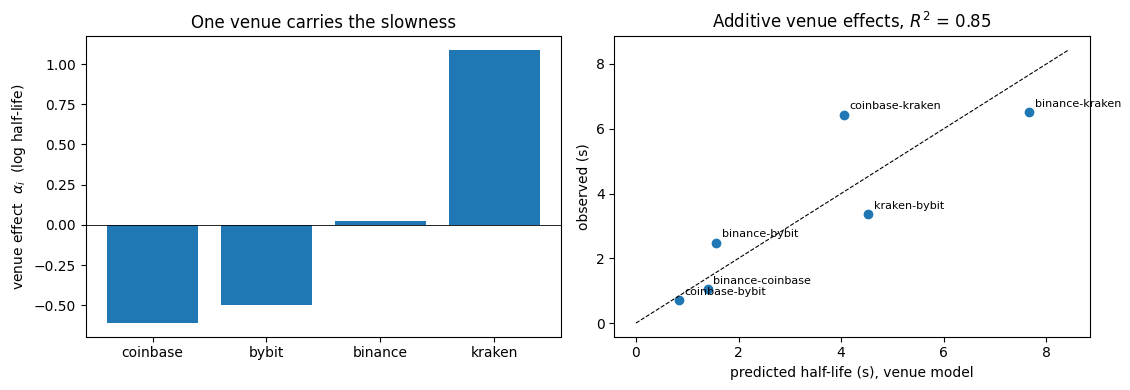

In [4]:
venues = ["binance", "bybit", "coinbase", "kraken"]
# Fit multiplicative speed differences as additive terms in log half-life.
y = np.log(summ["median"].values)
# A row marks the two venues belonging to that exchange pair.
X = np.zeros((len(summ), 1 + len(venues)))
X[:, 0] = 1.0
for k, p in enumerate(summ.pair):
    a, b = p.split("-")
    X[k, 1 + venues.index(a)] = 1.0
    X[k, 1 + venues.index(b)] = 1.0
Xc = np.vstack([X, [0.0] + [1.0]*len(venues)])      # constraint row: sum(alpha)=0
yc = np.concatenate([y, [0.0]])
coef, *_ = np.linalg.lstsq(Xc, yc, rcond=None)
mu, alphas = coef[0], dict(zip(venues, coef[1:]))
# R^2 here is an in-sample description of only six pair medians.
pred = X @ coef
r2 = 1 - ((y - pred)**2).sum() / ((y - y.mean())**2).sum()

print(f"mu (grand mean of log t) = {mu:+.2f}   ->   e^mu = {math.exp(mu):.2f} s")
for v, a in sorted(alphas.items(), key=lambda t: t[1]):
    print(f"  alpha_{v:<8s} = {a:+.2f}   (x{math.exp(a):.2f} multiplier on half-life)")
print(f"model R^2 on log median half-life: {r2:.2f}")
a, b = "coinbase", "kraken"
print(f"\nworked example  log t_CB,K = mu + a_CB + a_K = "
      f"{mu:+.2f} {alphas[a]:+.2f} {alphas[b]:+.2f} = {mu+alphas[a]+alphas[b]:+.2f}"
      f"  ->  {math.exp(mu+alphas[a]+alphas[b]):.2f} s   (observed "
      f"{summ.loc[summ.pair=='coinbase-kraken','median'].iloc[0]:.2f} s)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
vs = sorted(alphas, key=alphas.get)
axes[0].bar(vs, [alphas[v] for v in vs])
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_ylabel(r"venue effect  $\alpha_i$  (log half-life)")
axes[0].set_title("One venue carries the slowness")
axes[1].scatter(np.exp(pred), np.exp(y))
lim = [0, max(np.exp(y).max(), np.exp(pred).max()) * 1.1]
axes[1].plot(lim, lim, "k--", lw=0.8)
for k, p in enumerate(summ.pair):
    axes[1].annotate(p, (math.exp(pred[k]), math.exp(y[k])), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("predicted half-life (s), venue model")
axes[1].set_ylabel("observed (s)")
axes[1].set_title(f"Additive venue effects, $R^2$ = {r2:.2f}")
plt.tight_layout(); plt.show()

The venue model, blind to geography, explains most of the cross-pair variance; the
distance models explained none (with the wrong sign). $\alpha_{\mathrm{Kraken}}$ is the
dominant positive effect — dislocations on Kraken's pairs also *peak larger* before
anyone corrects them — which reads economically as **less arbitrage capital watching that
book**. The market graph's relevant metric is attention per node, not kilometers per edge.

## 4. Why the half-life needs a fine grid

One loose end: the 100 ms detection grid is a blurry stopwatch for *timing*. Sample-and-hold
turns a smooth decay into a staircase, which (a) lags — each held value is up to 100 ms
stale; (b) clips the peak — the true maximum falls between ticks; and (c) censors — a fit
needs 5 points, so decays under ~0.3–0.5 s fail or return garbage. All three biases push
measured half-lives **up**, worst for fast pairs. The two-stage design fixes this without
a 600-million-point grid: detect on 100 ms, then refit each event at 1 ms from the raw
nanosecond-stamped quotes inside its own window (`refine_events.py`), with per-event
update counts (`upd_A`, `upd_B`) to reject staircase artifacts.

            pair  median_coarse  p10_coarse  light_ms  n_fine  median_fine  p10_fine  frac_fine_lt_100ms  p10_fine_filtered
   binance-bybit          2.484       0.265 17.703396     491        0.913     0.070               0.145              0.075
 coinbase-kraken          6.437       0.421 19.641012     257        5.511     0.238               0.023              0.247
  binance-kraken          6.511       0.374 31.952446     370        3.350     0.178               0.038              0.184
binance-coinbase          1.041       0.247 36.290400     617        0.374     0.061               0.204              0.057
    kraken-bybit          3.361       0.330 36.335910     323        1.790     0.136               0.062              0.160
  coinbase-bybit          0.705       0.238 51.807552    1170        0.262     0.060               0.221              0.062

coarse grid inflated medians by 1.2x - 2.8x across pairs
update-count filter (>=10 on both legs) barely moves the floors -> not sta

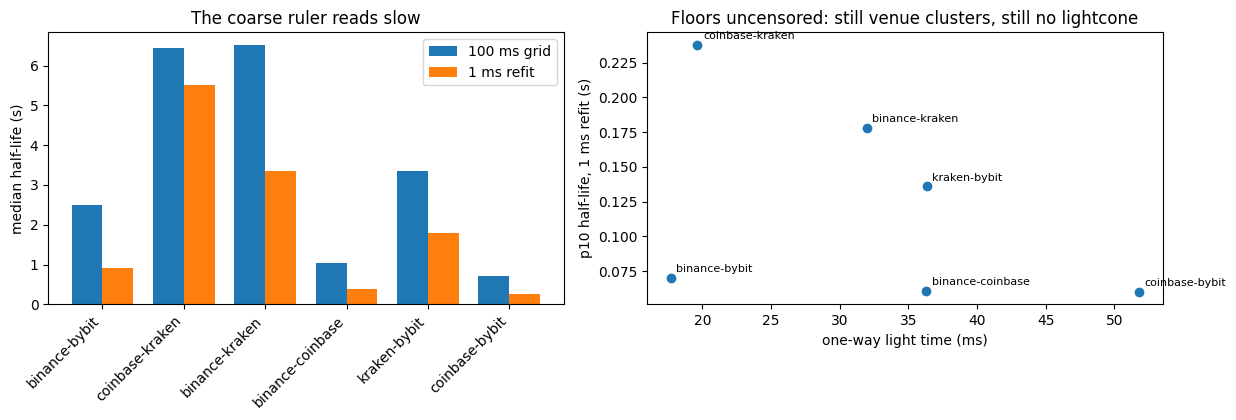

Spearman, fine p10 vs light-time: -0.54


In [5]:
# These fine fits were previously computed by refine_events.py from raw quotes.
# This cell summarizes the stored results; it does not reload or refit the quotes.
fine = ev[(ev.r2_fine >= MIN_R2) & ev.half_life_fine_s.notna()
          & (ev.half_life_fine_s < MAX_HL)].copy()
fine["min_upd"] = fine[["upd_A", "upd_B"]].min(axis=1)
# Coarse-clean and fine-clean masks can select DIFFERENT events.
# Section 5 adds a paired comparison to separate timing changes from selection.
fsum = (fine.groupby("pair").half_life_fine_s
        .agg(n_fine="size", median_fine="median",
             p10_fine=lambda x: x.quantile(0.10)).round(3))
cmp = summ.set_index("pair")[["median", "p10", "light_ms"]].join(fsum).reset_index()
cmp["frac_fine_lt_100ms"] = cmp.pair.map(
    fine.groupby("pair").half_life_fine_s.apply(lambda x: (x < 0.1).mean())).round(3)
# upd_A/upd_B count messages over the whole coarse event, not just its decay.
# The new section also reports changes during the actual fitted interval.
filt = fine[fine.min_upd >= 10]
cmp["p10_fine_filtered"] = cmp.pair.map(
    filt.groupby("pair").half_life_fine_s.quantile(0.10)).round(3)
print(cmp.rename(columns={"median": "median_coarse", "p10": "p10_coarse"})
         .to_string(index=False))
print(f"\ncoarse grid inflated medians by "
      f"{(cmp['median']/cmp['median_fine']).min():.1f}x - "
      f"{(cmp['median']/cmp['median_fine']).max():.1f}x across pairs")
print("update-count filter (>=10 on both legs) barely moves the floors -> not staircase artifacts")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
x = np.arange(len(cmp)); w = 0.38
axes[0].bar(x - w/2, cmp["median"], w, label="100 ms grid")
axes[0].bar(x + w/2, cmp["median_fine"], w, label="1 ms refit")
axes[0].set_xticks(x); axes[0].set_xticklabels(cmp.pair, rotation=45, ha="right")
axes[0].set_ylabel("median half-life (s)")
axes[0].set_title("The coarse ruler reads slow"); axes[0].legend()
axes[1].scatter(cmp.light_ms, cmp.p10_fine)
for _, r in cmp.iterrows():
    axes[1].annotate(r.pair, (r.light_ms, r.p10_fine), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("one-way light time (ms)")
axes[1].set_ylabel("p10 half-life, 1 ms refit (s)")
axes[1].set_title("Floors uncensored: still venue clusters, still no lightcone")
plt.tight_layout(); plt.show()

print(f"Spearman, fine p10 vs light-time: {spearman(cmp.light_ms, cmp.p10_fine):+.2f}")

## 5. A 1 ms refit that stops at the pre-event noise floor

**New sensitivity analysis — no noise-cutoff results are precomputed in this notebook.**
This section compares two fits to the **same raw-quote trajectory on the same 1 ms grid**:
a full post-peak fit within the detected window, and a fit that ends before the
background fluctuations become comparable to the residual. It does not change
`events.csv`, overwrite the existing fine-fit columns, or search for new events.

### 5.1 What is removed, and what remains?

For midpoint prices $P_A$ and $P_B$, write

$$d(t)=10^4\frac{P_A(t)-P_B(t)}{[P_A(t)+P_B(t)]/2}=b+s(t)+\epsilon(t).$$

The measured, baseline-corrected residual is $e(t)=d(t)-\hat b$. It still contains
both the event signal and background fluctuations; we cannot observe $\epsilon(t)$
separately. Using **only the 60 seconds strictly before the event**, estimate

$$\hat b=\operatorname{median}(d_{\rm pre}),\qquad
\hat\sigma_{\rm pre}=
\frac{Q_{0.75}(d_{\rm pre}-\hat b)-Q_{0.25}(d_{\rm pre}-\hat b)}{1.349}.$$

The IQR-based scale follows the form used in the supplied `analyze.py`. Here it is
computed over a **fixed pre-event minute**, not the detector's approximately five-minute
rolling residual window. The 60-second baseline and its 100 ms sampling step follow
`refine_events.py`. Thus **the event fit is at 1 ms; the background estimate remains at
100 ms**. These are deliberately separate settings, and the background estimate may
miss particularly short-lived fluctuations.

Set the amplitude cutoff to $h=K\hat\sigma_{\rm pre}$, initially **$K=2$**. Find the
largest $|e|$ on the fine grid, then keep the consecutive decay points **before the
first** $|e(t)|\le h$. Do not remove individual low points and resume fitting later.
For example, with $\hat\sigma_{\rm pre}=0.2$ bps, the cutoff is 0.4 bps; a path
$4\to2\to1\to0.5\to0.3\to0.7$ stops **before 0.3**, excluding the later rebound too.
An optional sign-change guard stops an overshoot that jumps across zero between samples.

The fit remains the supplied log-linear model,

$$\log|e(t)|=a+\beta(t-t_{\rm peak}),\qquad
 t_{1/2}=-\frac{\log 2}{\beta},\quad \beta<0.$$

**Interpretation:** $K=2$ is an adjustable analysis choice, not a known physical noise
boundary or a guarantee of a noise-free signal. A first-crossing cutoff can itself
change the fitted slope and event selection. Compare identical accepted events and
check several pre-specified $K$ values rather than choosing the most attractive result.
All reported $R^2$ values below are calculated **in log-residual space**.

**Inputs required:** the event table (or the event columns retained in a refined table)
**and both venues' raw `quotes_<venue>_*.csv` files**. The event table alone is not enough.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---- Paths: relative to the directory from which Jupyter was launched. ----
# Set this explicitly to your complete raw-data folder if auto-detection is wrong.
_nf_candidates = [Path("data_week"), Path("data"), Path(".")]
NF_RAW_DIR = next(
    (p for p in _nf_candidates if p.is_dir() and any(p.glob("quotes_*.csv"))),
    Path("data_week"),
)
_nf_tables = [Path("results_week/events.csv"), Path("events.csv"),
              Path(globals().get("REFINED", "refined_events.csv"))]
NF_EVENT_TABLE = next((p for p in _nf_tables if p.is_file()), _nf_tables[0])
NF_OUTPUT_DIR = Path("results_noise_floor_1ms")   # New files only; originals stay unchanged.

# ---- Numerical grid and pre-event background estimate. ----
NF_GRID_MS = 1.0                  # Actual event refitting grid: one millisecond.
NF_PRE_SECONDS = 60.0             # Strictly before t_start; never use the future tail.
NF_PRE_GRID_MS = 100.0            # Same background grid as refine_events.py.
NF_MAX_QUOTE_AGE_S = 10.0          # Inherited stale-quote limit, NOT a timing-accuracy claim.
NF_MIN_PRE_POINTS = 30            # Same minimum as the original refiner; coverage is reported.

# ---- Noise cutoff and sensitivity settings. ----
NF_MAIN_K = 2.0                   # Stop when |gap - baseline| first reaches 2 sigma_pre.
NF_K_VALUES = (2.0,)              # Optional sensitivity run: (1.5, 2.0, 3.0).
NF_STOP_ON_SIGN_FLIP = True       # Also stop if a jump overshoots to the opposite sign.
NF_MIN_SIGMA_BPS = 1e-12          # Numerical-zero test, NOT an assumed market noise floor.

# ---- Fit-quality criteria. Keep them the same for both refits. ----
NF_MIN_FIT_POINTS = 5             # Grid points; NOT five independent quote updates.
NF_MIN_R2 = float(globals().get("MIN_R2", 0.5))
NF_MAX_HALF_LIFE_S = float(globals().get("MAX_HL", 120.0))
NF_MAX_EVENT_S = 120.0            # Same window cap used in the previous analysis.
NF_PRICE_CHANGE_FLAG = 3         # Diagnostic flag only; not part of the primary clean mask.
NF_LIMIT_EVENTS = None           # Set to e.g. 100 for an explicitly labeled smoke run.

if not any(np.isclose(NF_MAIN_K, k) for k in NF_K_VALUES):
    raise ValueError("NF_MAIN_K must also appear in NF_K_VALUES.")
if any(not np.isfinite(k) or k <= 0 for k in NF_K_VALUES):
    raise ValueError("Every cutoff multiplier must be finite and positive.")
if NF_GRID_MS <= 0 or NF_PRE_GRID_MS <= 0:
    raise ValueError("Grid steps must be positive.")
print("Raw quotes:", NF_RAW_DIR.resolve())
print("Event table:", NF_EVENT_TABLE)
print("New outputs:", NF_OUTPUT_DIR)

### 5.2 Load genuine raw updates and reconstruct the observed gap

`events.csv` supplies **where to look**, not the fine quote values. The loader reads
`bid`, `ask`, and integer `local_ts_ns`, sorts the observations, and keeps the final
record when timestamps are identical. As in `refine_events.py`, each grid time uses
the most recent quote available at or before that time—no linear interpolation and
no future quote. The resulting curve is a sample-and-hold representation of received
quotes, not 1,000 independent observations per second.

The loader reads in chunks and keeps only the dates needed for the selected events,
including the pre-event minute and a seed interval. It still holds the retained raw
arrays for the required venues in memory. Baseline coverage and actual midpoint-change
counts are retained as diagnostics; a fine grid cannot repair stale or missing quotes.

In [ ]:
def nf_load_raw(directory, venue, lo_ns, hi_ns):
    """Read raw quotes once per venue, retaining exact integer nanosecond timestamps."""
    paths = sorted(Path(directory).glob(f"quotes_{venue}_*.csv"))
    if not paths:
        raise FileNotFoundError(f"Missing quotes_{venue}_*.csv in {directory}")
    chunks_ts, chunks_mid = [], []
    for path in paths:
        # Read timestamps as text first: converting epoch nanoseconds through a float
        # can lose low-order digits. Price columns can safely be ordinary floats.
        for chunk in pd.read_csv(path, usecols=["bid", "ask", "local_ts_ns"],
                                 dtype={"local_ts_ns": "string"},
                                 chunksize=250_000, on_bad_lines="skip"):
            stamp = chunk["local_ts_ns"]
            integer_stamp = stamp.str.fullmatch(r"\d+", na=False)
            chunk = chunk.loc[integer_stamp].copy()
            if chunk.empty:
                continue
            ts = chunk["local_ts_ns"].astype("int64").to_numpy()
            bid = pd.to_numeric(chunk["bid"], errors="coerce").to_numpy(float)
            ask = pd.to_numeric(chunk["ask"], errors="coerce").to_numpy(float)
            keep = ((ts >= lo_ns) & (ts <= hi_ns) & np.isfinite(bid)
                    & np.isfinite(ask) & (bid > 0) & (ask >= bid))
            if keep.any():
                chunks_ts.append(ts[keep])
                chunks_mid.append((bid[keep] + ask[keep]) / 2.0)
    if not chunks_ts:
        return {"ts": np.array([], dtype=np.int64), "mid": np.array([], dtype=float),
                "change_ts": np.array([], dtype=np.int64)}
    ts, mid = np.concatenate(chunks_ts), np.concatenate(chunks_mid)
    order = np.argsort(ts, kind="stable")
    ts, mid = ts[order], mid[order]
    keep = np.r_[ts[1:] != ts[:-1], True]  # Keep last record at each identical timestamp.
    ts, mid = ts[keep], mid[keep]
    # A new message need not change the midpoint. Count midpoint changes separately.
    changes = ts[1:][mid[1:] != mid[:-1]]
    return {"ts": ts, "mid": mid, "change_ts": changes}


def nf_asof(raw_venue, grid_ns):
    """Return latest observed midpoint and quote age at each grid time."""
    ts, mid = raw_venue["ts"], raw_venue["mid"]
    values = np.full(len(grid_ns), np.nan)
    ages = np.full(len(grid_ns), np.inf)
    if not len(ts):
        return values, ages
    idx = np.searchsorted(ts, grid_ns, side="right") - 1
    ok = idx >= 0
    values[ok] = mid[idx[ok]]
    ages[ok] = (grid_ns[ok] - ts[idx[ok]]) / 1e9
    return values, ages


def nf_gap(raw_a, raw_b, grid_ns):
    """Signed midpoint difference in basis points, plus a usable-quote mask."""
    a, age_a = nf_asof(raw_a, grid_ns)
    b, age_b = nf_asof(raw_b, grid_ns)
    valid = (np.isfinite(a) & np.isfinite(b)
             & (age_a < NF_MAX_QUOTE_AGE_S) & (age_b < NF_MAX_QUOTE_AGE_S))
    gap = np.full(len(grid_ns), np.nan)
    gap[valid] = 1e4 * (a[valid] - b[valid]) / ((a[valid] + b[valid]) / 2.0)
    return gap, valid


def nf_prepare_event(row, raw):
    """Build one event's baseline and fine path; no fitting or denoising here."""
    a, b = row["pair"].split("-")
    t0 = int(pd.Timestamp(row["t_start"]).value)
    duration = float(row["duration_s"])
    if not np.isfinite(duration) or duration <= 0:
        return None, "invalid_duration"
    t1 = t0 + int(round(min(duration, NF_MAX_EVENT_S) * 1e9))
    pre_step = int(round(NF_PRE_GRID_MS * 1e6))
    step = int(round(NF_GRID_MS * 1e6))
    pre_grid = np.arange(t0 - int(NF_PRE_SECONDS * 1e9), t0, pre_step, dtype=np.int64)
    pre_gap, pre_ok = nf_gap(raw[a], raw[b], pre_grid)
    if pre_ok.sum() < NF_MIN_PRE_POINTS:
        return None, "insufficient_pre_event_quotes"

    # Estimate the center and scale from exactly the same fixed pre-event sample.
    # IQR / 1.349 is a Gaussian-calibrated robust scale, not knowledge of epsilon(t).
    baseline = float(np.median(pre_gap[pre_ok]))
    pre_residual = pre_gap[pre_ok] - baseline
    q25, q75 = np.quantile(pre_residual, [0.25, 0.75])
    sigma = float((q75 - q25) / 1.349)

    # Do not extend the coarse event window; the fine grid only refits inside it.
    grid = np.arange(t0, t1 + 1, step, dtype=np.int64)
    gap, valid = nf_gap(raw[a], raw[b], grid)
    valid_ids = np.flatnonzero(valid)
    if not len(valid_ids):
        return None, "no_valid_event_quotes"
    residual = gap - baseline
    peak = int(valid_ids[np.argmax(np.abs(residual[valid_ids]))])

    # A common safety rule for BOTH fits: never bridge a missing/stale-quote gap
    # after the peak. The full reference can therefore differ from the old script
    # on windows where that script simply dropped missing points and continued.
    bad = np.flatnonzero(~valid[peak:])
    end = peak + int(bad[0]) if len(bad) else len(grid)
    return {"grid": grid, "e": residual, "valid": valid, "peak": peak,
            "end": end, "baseline": baseline, "sigma": sigma,
            "pre_valid_fraction": float(pre_ok.mean()),
            "event_valid_fraction": float(valid.mean()),
            "full_stop": "invalid_quote" if len(bad) else "window_end",
            "a": a, "b": b}, "ok"

### 5.3 Stop once, then fit only the retained prefix

The cutoff sample is **excluded**. Later points stay excluded even if the residual
rises above the cutoff again. If the peak is already below the cutoff, the noise scale
is zero/unusable, or too few points remain, the row receives a rejection reason instead
of a fabricated half-life. A zero IQR does **not** establish a noiseless market.

Both fits use the same peak and the same available post-peak window. As a shared safety
rule, neither crosses a missing/stale-quote interval. The cutoff version additionally
stops at the noise floor (or, when enabled, a sign reversal). This controlled full-window
reference is recomputed here; the earlier `half_life_fine_s` column is preserved for
comparison, not overwritten.

Quote counts below refer to the **actual fitted interval**, after the peak through its
last included grid sample. They exclude the quote that supplies the initial state.
They are diagnostics, not a claim that each update is independent. We also report
whether even one fitted half-life is covered by the retained span.

In [ ]:
def nf_stop_index(signed_post_peak, sigma, k):
    """Return exclusive end index and reason; NEVER resume after a first crossing."""
    e = np.asarray(signed_post_peak, float)
    if not len(e):
        return 0, "empty_decay"
    if not np.isfinite(sigma) or sigma <= NF_MIN_SIGMA_BPS:
        return 0, "unusable_noise_scale"
    floor = k * sigma
    if abs(e[0]) <= floor:
        return 0, "peak_not_above_floor"
    below = np.flatnonzero(np.abs(e) <= floor)
    end = int(below[0]) if len(below) else len(e)
    reason = "noise_floor" if len(below) else "window_end"
    if NF_STOP_ON_SIGN_FLIP:
        # A jump can skip over the small-|e| band entirely; do not fit its other side.
        reverse = np.flatnonzero(np.sign(e) != np.sign(e[0]))
        if len(reverse) and int(reverse[0]) < end:
            end, reason = int(reverse[0]), "sign_flip"
    return end, reason


def nf_log_fit(t, absolute_residual):
    """OLS fit of log|e| versus seconds since peak; R^2 is in LOG space."""
    t, y = np.asarray(t, float), np.asarray(absolute_residual, float)
    keep = np.isfinite(t) & np.isfinite(y) & (y > 1e-9)
    t, y = t[keep], y[keep]
    result = {"half_life_s": np.nan, "r2": np.nan, "slope": np.nan,
              "intercept": np.nan, "n_grid": int(len(t)),
              "span_s": float(t[-1] - t[0]) if len(t) else 0.0,
              "clean": False, "status": "too_few_points"}
    if len(t) < NF_MIN_FIT_POINTS or result["span_s"] <= 0:
        return result
    log_y = np.log(y)
    total = float(np.sum((log_y - log_y.mean()) ** 2))
    if total <= 1e-24:
        result["status"] = "flat_decay"
        return result
    slope, intercept = np.polyfit(t, log_y, 1)
    pred = slope * t + intercept
    r2 = 1.0 - float(np.sum((log_y - pred) ** 2)) / total
    result.update(slope=float(slope), intercept=float(intercept), r2=float(r2))
    if not np.isfinite(slope) or slope >= 0:
        result["status"] = "nondecaying_slope"
        return result
    hl = float(-np.log(2.0) / slope)
    result["half_life_s"] = hl
    if not np.isfinite(hl) or not (0 < hl < NF_MAX_HALF_LIFE_S):
        result["status"] = "half_life_out_of_range"
    elif not np.isfinite(r2) or r2 < NF_MIN_R2:
        result["status"] = "low_r2"
    else:
        result.update(clean=True, status="ok")
    return result


def nf_count_between(timestamps, left, right):
    """Number of raw records in (left, right]; the seed state at left is not an update."""
    if right <= left:
        return 0
    return int(np.searchsorted(timestamps, right, side="right")
               - np.searchsorted(timestamps, left, side="right"))


def nf_measure_path(path, raw, k):
    """Fit full and noise-stopped decays, with identical baseline, grid and peak."""
    peak, end = path["peak"], path["end"]
    stamps = path["grid"][peak:end]
    e = path["e"][peak:end]
    t = (stamps - stamps[0]) / 1e9
    full = nf_log_fit(t, np.abs(e))
    stop, reason = nf_stop_index(e, path["sigma"], k)
    if reason == "window_end":
        reason = path["full_stop"]  # Could instead end because a quote became invalid.
    cut = nf_log_fit(t[:stop], np.abs(e[:stop]))
    if stop == 0:
        cut["status"] = reason

    out = {"nf_k": float(k), "nf_grid_ms": NF_GRID_MS,
           "nf_baseline_bps": path["baseline"], "nf_sigma_pre_bps": path["sigma"],
           "nf_cutoff_bps": k * path["sigma"],
           "nf_pre_valid_fraction": path["pre_valid_fraction"],
           "nf_event_valid_fraction": path["event_valid_fraction"],
           "nf_peak_utc": pd.to_datetime(int(stamps[0]), unit="ns", utc=True),
           "nf_peak_bps": float(abs(e[0])), "nf_stop_reason": reason,
           "nf_full_stop_reason": path["full_stop"],
           "nf_trimmed": bool(stop < len(e)),
           "nf_stop_after_peak_s": float(t[stop]) if stop < len(t) else np.nan}
    for prefix, fit in (("full1ms", full), ("nf", cut)):
        out.update({f"{prefix}_{name}": val for name, val in fit.items()})
    # Count messages and midpoint CHANGES only during the noise-stopped fitted span.
    last = int(stamps[stop - 1]) if stop else int(stamps[0])
    for label, venue in (("A", path["a"]), ("B", path["b"])):
        out[f"nf_fit_upd_{label}"] = nf_count_between(raw[venue]["ts"], stamps[0], last)
        out[f"nf_fit_mid_changes_{label}"] = nf_count_between(
            raw[venue]["change_ts"], stamps[0], last)
    out["nf_min_mid_changes"] = min(out["nf_fit_mid_changes_A"],
                                     out["nf_fit_mid_changes_B"])
    out["nf_update_support_flag"] = out["nf_min_mid_changes"] >= NF_PRICE_CHANGE_FLAG
    hl = cut["half_life_s"]
    out["nf_half_lives_covered"] = cut["span_s"] / hl if np.isfinite(hl) and hl > 0 else np.nan
    out["nf_covers_one_half_life"] = bool(out["nf_half_lives_covered"] >= 1)
    out["nf_paired_clean"] = bool(full["clean"] and cut["clean"])
    return out

In [ ]:
# Small SYNTHETIC check: proves the cutoff excludes a rebound rather than masking
# only the low points. These values are a unit test, not observations from your files.
_nf_toy_t = np.arange(26) * 0.02       # 20 ms apart, true half-life 100 ms.
_nf_toy_e = 4.0 * 2.0 ** (-_nf_toy_t / 0.1)
_nf_toy_e[20:] = 0.7                 # Artificial rebound AFTER the first floor crossing.
_nf_end, _nf_reason = nf_stop_index(_nf_toy_e, sigma=0.2, k=2.0)
assert _nf_end == 17 and _nf_reason == "noise_floor"
_nf_test_fit = nf_log_fit(_nf_toy_t[:_nf_end], _nf_toy_e[:_nf_end])
assert np.isclose(_nf_test_fit["half_life_s"], 0.1)
print("Synthetic sanity check passed: 100 ms half-life recovered; later rebound excluded.")

### 5.4 Run the refit and save a separate result table

The next cell checks for **all required venues before starting**. When raw data are
missing, it prints the missing filename patterns and skips the calculation; it does
not invent results or silently use only the available Binance quotes. Once the full
raw folder is available, set `NF_RAW_DIR` and rerun this section.

One event is reconstructed at a time, so there is no week-long 1 ms grid. Each selected
$K$ reuses that event's path. The default runs only $K=2$; set
`NF_K_VALUES = (1.5, 2.0, 3.0)` for the optional sensitivity table. Every attempted row,
including failures, is retained with a status so changes in sample selection are visible.

In [ ]:
nf_results = pd.DataFrame()
nf_runs = pd.DataFrame()
nf_raw = {}
nf_input = pd.DataFrame()

if not NF_EVENT_TABLE.is_file():
    print(f"Not run: event table not found: {NF_EVENT_TABLE}")
else:
    nf_input = pd.read_csv(NF_EVENT_TABLE)
    required = {"pair", "t_start", "duration_s"}
    if not required.issubset(nf_input.columns):
        raise ValueError(f"Event table needs columns {sorted(required)}")
    nf_input["t_start"] = pd.to_datetime(nf_input["t_start"], utc=True, format="ISO8601")
    nf_input.insert(0, "nf_input_row", np.arange(len(nf_input)))
    if NF_LIMIT_EVENTS is not None:
        nf_input = nf_input.head(int(NF_LIMIT_EVENTS)).copy()
        print(f"SMOKE RUN ONLY: first {len(nf_input)} event rows; not a full-data result.")
    if nf_input.empty or nf_input["t_start"].isna().any():
        raise ValueError("Input is empty or contains an invalid event start time.")
    nf_venues = sorted({v for p in nf_input["pair"].unique() for v in p.split("-")})
    nf_missing = [v for v in nf_venues if not list(NF_RAW_DIR.glob(f"quotes_{v}_*.csv"))]
    if nf_missing:
        print("Not run: this analysis needs raw quotes from both legs of every pair.")
        print("Missing:", ", ".join(f"quotes_{v}_*.csv" for v in nf_missing))
        print("Set NF_RAW_DIR to the complete raw-data folder, then rerun Section 5.")
    else:
        # Include seed quotes before the pre-event baseline, so as-of alignment works.
        nf_lo = int(nf_input["t_start"].min().value) - int(
            (NF_PRE_SECONDS + NF_MAX_QUOTE_AGE_S) * 1e9)
        nf_end_times = nf_input["t_start"] + pd.to_timedelta(
            pd.to_numeric(nf_input["duration_s"], errors="coerce").clip(0, NF_MAX_EVENT_S),
            unit="s")
        nf_hi = int(nf_end_times.max().value)
        for venue in nf_venues:
            nf_raw[venue] = nf_load_raw(NF_RAW_DIR, venue, nf_lo, nf_hi)
            print(f"Loaded {venue}: {len(nf_raw[venue]['ts']):,} raw records, "
                  f"{len(nf_raw[venue]['change_ts']):,} midpoint changes")

        nf_records = []
        for count, row in enumerate(nf_input.to_dict("records"), 1):
            path, status = nf_prepare_event(row, nf_raw)
            for k in NF_K_VALUES:
                if path is None:
                    measured = {"nf_k": float(k), "nf_grid_ms": NF_GRID_MS,
                                "nf_status": status, "full1ms_status": status,
                                "nf_clean": False, "full1ms_clean": False,
                                "nf_paired_clean": False, "nf_trimmed": False}
                else:
                    measured = nf_measure_path(path, nf_raw, k)
                nf_records.append({**row, **measured})
            if count % 1000 == 0:
                print(f"Processed {count:,}/{len(nf_input):,} event windows")

        nf_runs = pd.DataFrame(nf_records)
        # Ensure an all-rejected run still has the columns expected by later cells.
        for col in ("nf_half_life_s", "full1ms_half_life_s", "nf_r2", "full1ms_r2",
                    "nf_min_mid_changes", "nf_sigma_pre_bps", "nf_cutoff_bps"):
            if col not in nf_runs:
                nf_runs[col] = np.nan
        nf_results = nf_runs[np.isclose(nf_runs["nf_k"], NF_MAIN_K)].copy()
        NF_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        nf_output = NF_OUTPUT_DIR / "refined_events_noise_floor_1ms.csv"
        nf_results.to_csv(nf_output, index=False)  # Original event/fine columns stay intact.
        if len(NF_K_VALUES) > 1:
            nf_runs.to_csv(NF_OUTPUT_DIR / "noise_floor_sensitivity_events.csv", index=False)
        settings = {name: str(value) if isinstance(value, Path) else value
                    for name, value in list(globals().items())
                    if name.startswith("NF_") and isinstance(
                        value, (str, int, float, bool, tuple, list, Path, type(None)))}
        (NF_OUTPUT_DIR / "noise_floor_settings.json").write_text(
            json.dumps(settings, indent=2), encoding="utf-8")
        print(f"Wrote {len(nf_results):,} attempted event rows to {nf_output}")
        print(f"Clean full-reference fits: {int(nf_results['full1ms_clean'].sum()):,}; "
              f"clean cutoff fits: {int(nf_results['nf_clean'].sum()):,}; "
              f"clean in BOTH: {int(nf_results['nf_paired_clean'].sum()):,}")

### 5.5 Compare the same events, and inspect why fits were rejected

The primary table reports separate acceptance counts, but its medians, 10th percentiles,
and event-by-event ratios use **only rows clean in both refits**. A change in the clean
population must not be described as a timing change for the same events.

`median_event_ratio` is the median of $t_{1/2,\rm cutoff}/t_{1/2,\rm full}$, **not** the
ratio of two medians. `cutoff_lt_100ms_paired` refers to fitted half-lives below 100 ms,
not events whose total duration is below 100 ms. The price-change column flags sparse
support during the fitted decay; its threshold is diagnostic, not a statistical proof.
When multiple $K$ values are used, `n_common_all_k` and the final median columns compare
the stricter set accepted at **every** tested cutoff.

In [ ]:
nf_summary = pd.DataFrame()
if nf_runs.empty:
    print("No noise-floor results yet. Provide the complete raw data and run Section 5.4.")
else:
    # Common across ALL K values: protects the sensitivity comparison from K-specific
    # event selection. The primary within-K comparison also requires both fits clean.
    accepted_sets = [set(g.loc[g["nf_paired_clean"], "nf_input_row"])
                     for _, g in nf_runs.groupby("nf_k")]
    common_all_k = set.intersection(*accepted_sets) if accepted_sets else set()
    rows = []
    for (k, pair), group in nf_runs.groupby(["nf_k", "pair"], sort=True):
        paired = group.loc[group["nf_paired_clean"]]
        stable = group.loc[group["nf_input_row"].isin(common_all_k)]
        full = paired["full1ms_half_life_s"]
        cut = paired["nf_half_life_s"]
        rows.append({
            "K": k, "pair": pair, "n_attempted": len(group),
            "n_clean_full": int(group["full1ms_clean"].sum()),
            "n_clean_cutoff": int(group["nf_clean"].sum()), "n_paired": len(paired),
            "median_full_paired_s": full.median(), "median_cutoff_paired_s": cut.median(),
            "p10_full_paired_ms": 1000 * full.quantile(0.1),
            "p10_cutoff_paired_ms": 1000 * cut.quantile(0.1),
            "median_event_ratio": (cut / full).median(),
            "cutoff_lt_100ms_paired": (cut < 0.1).mean() if len(cut) else np.nan,
            "n_paired_price_change_flag": int((paired["nf_min_mid_changes"] >=
                                               NF_PRICE_CHANGE_FLAG).sum()),
            "n_common_all_k": len(stable),
            "median_cutoff_common_all_k_s": stable["nf_half_life_s"].median(),
        })
    nf_summary = pd.DataFrame(rows)
    display(nf_summary.round(4))
    nf_summary.to_csv(NF_OUTPUT_DIR / "noise_floor_paired_summary.csv", index=False)
    print("Rejection/status counts (all attempts, including successful fits):")
    display(pd.crosstab(nf_runs["nf_k"], nf_runs["nf_status"]))

    # One chart, one axis; the points for each pair use exactly the same event subset.
    main_summary = nf_summary[np.isclose(nf_summary["K"], NF_MAIN_K)]
    shown = main_summary[main_summary["n_paired"] > 0]
    if not shown.empty:
        fig, ax = plt.subplots(figsize=(9, 4.6))
        x = np.arange(len(shown))
        ax.plot(x, shown["median_full_paired_s"], "o--", label="Full post-peak 1 ms reference")
        ax.plot(x, shown["median_cutoff_paired_s"], "s-", label=f"Stop at {NF_MAIN_K:g} sigma_pre")
        ax.set_xticks(x)
        ax.set_xticklabels(shown["pair"], rotation=30, ha="right")
        ax.set_ylabel("Median fitted half-life (s); same events")
        ax.set_title("Does excluding the near-noise tail change the fitted half-life?")
        ax.legend()
        fig.tight_layout()
        plt.show()

### 5.6 Inspect one real event before interpreting the summaries

This plot is generated only after the raw-data refit succeeds. By default it chooses
the first clean paired event that actually hit the noise cutoff; set
`NF_EXAMPLE_INPUT_ROW` to inspect any specific row. This is a diagnostic example, not
a representative-event claim. The cutoff line has units of **bps**; it is unrelated
to the separate timestamp-jitter limitation, which has units of **milliseconds**.

In [ ]:
NF_EXAMPLE_INPUT_ROW = None       # e.g. 521 refers to nf_input_row, not a sorted table position.
if nf_results.empty or not nf_raw:
    print("Event plot skipped: no raw-data noise-floor results are available yet.")
else:
    choices = nf_results.loc[nf_results["nf_paired_clean"]].copy()
    if NF_EXAMPLE_INPUT_ROW is not None:
        choices = nf_results.loc[nf_results["nf_input_row"] == NF_EXAMPLE_INPUT_ROW]
    elif "nf_stop_reason" in choices:
        trimmed = choices.loc[choices["nf_stop_reason"] == "noise_floor"]
        if not trimmed.empty:
            choices = trimmed
    if choices.empty:
        print("No suitable event for the example plot; inspect the status table above.")
    else:
        row = choices.iloc[0].to_dict()
        path, status = nf_prepare_event(row, nf_raw)
        if path is None:
            print("Example could not be reconstructed:", status)
        else:
            peak, end = path["peak"], path["end"]
            grid, e = path["grid"], path["e"]
            t = (grid - grid[peak]) / 1e9
            stop, reason = nf_stop_index(e[peak:end], path["sigma"], NF_MAIN_K)
            full_fit = nf_log_fit(t[peak:end], np.abs(e[peak:end]))
            cut_fit = nf_log_fit(t[peak:peak + stop], np.abs(e[peak:peak + stop]))
            fig, ax = plt.subplots(figsize=(10, 4.8))
            ax.step(t, np.abs(e), where="post", label="Observed |gap - pre-event median|", alpha=0.65)
            for fit, times, label, style in (
                (full_fit, t[peak:end], "Full-window log-linear fit", "--"),
                (cut_fit, t[peak:peak + stop], "Noise-stopped log-linear fit", "-"),
            ):
                if np.isfinite(fit["slope"]):
                    ax.plot(times, np.exp(fit["intercept"] + fit["slope"] * times),
                            linestyle=style, linewidth=2, label=label)
            ax.axhline(NF_MAIN_K * path["sigma"], linestyle=":",
                       label=f"Noise cutoff = {NF_MAIN_K:g} sigma_pre")
            if stop < end - peak:
                ax.axvline(t[peak + stop], linestyle="--", label=f"First stop: {reason}")
            ax.set_xlabel("Time relative to fine-grid peak (s)")
            ax.set_ylabel("Absolute baseline-corrected gap (bps)")
            ax.set_title(f"{row['pair']} | input row {int(row['nf_input_row'])} | {row['t_start']}")
            ax.legend(fontsize=8)
            fig.tight_layout()
            plt.show()
            print(f"Estimated baseline = {path['baseline']:.4g} bps; "
                  f"sigma_pre = {path['sigma']:.4g} bps; cutoff = {NF_MAIN_K*path['sigma']:.4g} bps")
            print("Fit update counts and coverage:")
            display(choices.iloc[[0]][[c for c in (
                "nf_fit_upd_A", "nf_fit_upd_B", "nf_fit_mid_changes_A", "nf_fit_mid_changes_B",
                "nf_half_lives_covered", "nf_pre_valid_fraction", "nf_r2", "nf_stop_reason")
                if c in choices.columns]])

### 5.7 How to interpret this check

A shorter cutoff half-life would be **consistent with** a slowly fluctuating tail
flattening the original log fit; a longer one is also possible. Neither direction is
guaranteed. A changed $R^2$ describes different fitted intervals, not automatic proof
that one estimator is closer to the true signal. Report the paired results, acceptance
counts, and cutoff sensitivity together.

The estimated background scale includes ordinary price-gap variation and feed effects.
It is not a separately observed $\epsilon(t)$. Previous dislocations, a drifting basis,
or a change in volatility can contaminate the pre-event minute. A near-zero IQR, poor
baseline coverage, a short retained span, or very few midpoint changes should trigger
inspection—not a claim of precise sub-100-ms market dynamics. Refining the grid does
not remove receive-time jitter.

**Scope and provenance.** This added section follows the supplied `refine_events.py`
for raw midpoints, as-of alignment, the pre-event minute, and the log-linear fit; the
IQR/1.349 scale follows the form in `analyze.py`. The cutoff, optional sign-change guard,
shared no-gap rule, and diagnostics are new analysis choices documented above. Only
Sections 5.4–5.6 compute new market results. The synthetic check is not market evidence.
The original Sections 1–4 and their saved results are retained, with additional code
comments; this section does not independently verify their geographical or causal claims.

## 6. Conclusion

> **Scope note for the added analysis:** the original conclusion below is retained. It describes Sections 1–4, not the new noise-floor refit. Evaluate Section 5 before extending any result to that estimator.

Across two distance metrics (physical lower bound; measured network RTT), two resolutions
(100 ms; 1 ms), and two statistics (median; tenth-percentile floor), the answer is the
same: **no positive distance dependence** — the farthest pair is consistently the fastest —
while an additive venue-effects model $\log t_{ij} = \mu + \alpha_i + \alpha_j$ captures
the structure, with $\alpha_{\mathrm{Kraken}}$ the dominant slow term at every quantile.
At publicly observable timescales, cross-exchange convergence in BTC is bounded by
**per-venue arbitrage attention**, not by information propagation.

The claim's honest boundary: the fastest floors cluster near 60–70 ms, which is plausibly
the dissemination-and-jitter floor of public WebSocket feeds observed from one vantage
point — so a geometric lightcone below that scale is neither confirmed nor excluded.
Probing it needs region-local probes (the \$2 mesh) and, ideally, exchange-side
timestamps — the natural sequel, alongside a transfer-entropy lead-lag test of *which*
venue originates price discovery.